In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score

In [2]:
# Dataset can be downloaded here:
# https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
## Data preparation

# Fill missing values
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

print(df.isnull().sum())

for c in categorical:
    df[c] = df[c].fillna('NA')
for c in numerical:
    df[c] = df[c].fillna(0.0)

# Split the data
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [5]:
# ROC AUC Feature importance
for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    print(c, round(auc, 4))

annual_income 0.6082
number_of_courses_viewed 0.723
interaction_count 0.7649
lead_score 0.7882


In [6]:
## Model training
features = categorical + numerical

def train_model(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_tr[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model

def predict(dv, model, df_v):
    X = dv.transform(df_v[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

In [7]:
# Model AUC
dv, model = train_model(df_train, y_train)
y_pred = predict(dv, model, df_val)
print('AUC =', round(roc_auc_score(y_val, y_pred), 3))

AUC = 0.732


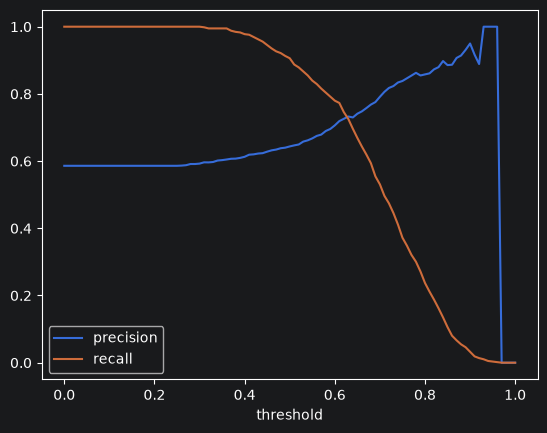

intersection threshold = 0.63


In [8]:
# Precision and recall
thresholds = np.arange(0, 1.01, 0.01)
precisions, recalls = [], []
for t in thresholds:
    pred = (y_pred >= t).astype(int)
    precisions.append(precision_score(y_val, pred, zero_division=0))
    recalls.append(recall_score(y_val, pred, zero_division=0))

plt.plot(thresholds, precisions, label='precision')
plt.plot(thresholds, recalls, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

best_t, best_diff = None, 10
for t, p, r in zip(thresholds, precisions, recalls):
    if p == 0 and r == 0:
        continue
    if abs(p - r) < best_diff:
        best_diff = abs(p - r)
        best_t = round(t, 2)
print('intersection threshold =', best_t)
# Answer Q3: 0.63

In [11]:
# F1 Score
best_t, best_f1 = None, -1
for t, p, r in zip(thresholds, precisions, recalls):
    f1 = 0 if (p + r) == 0 else 2 * p * r / (p + r)
    if f1 > best_f1:
        best_f1 = f1
        best_t = round(t, 2)
print('best =', best_t, '-> F1 =', round(best_f1, 4))

best = 0.41 -> F1 = 0.7576


In [12]:
# 5-Fold CV Standard Deviation
def cross_validate(C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        d_tr = df_full_train.iloc[train_idx]
        d_va = df_full_train.iloc[val_idx]
        dv_f, model_f = train_model(d_tr, d_tr['converted'].values, C)
        pred = predict(dv_f, model_f, d_va)
        scores.append(roc_auc_score(d_va['converted'].values, pred))
    return np.array(scores)


scores = cross_validate(1.0)
print('mean =', round(scores.mean(), 3), 'std =', round(scores.std(), 3))

mean = 0.732 std = 0.007


In [13]:
# Hyperparameter Tuning
for C in [0.000001, 0.001, 1]:
    scores = cross_validate(C)
    print('C =', C, '-> mean =', round(scores.mean(), 3), 'std =', round(scores.std(), 3))

C = 1e-06 -> mean = 0.617 std = 0.019
C = 0.001 -> mean = 0.749 std = 0.01
C = 1 -> mean = 0.732 std = 0.007
